## **2. Класифікація зображень за допомогою CNN**

У цій частині лабораторної роботи досліджується застосування згорткових нейронних мереж  для класифікації зображень. На відміну від повнозв'язних нейронних мереж, згорткові мережі здатні автоматично виявляти просторові ознаки зображень, зокрема контури, текстури та складніші візуальні структури.

Для експерименту використовується датасет Oxford-IIIT Pet, який містить зображення 37 порід котів і собак. Завдання полягає у визначенні породи тварини за її зображенням.

У роботі буде реалізовано дві моделі: власну згорткову нейронну мережу та ResNet18 із попередньо навченими вагами. Це дасть змогу порівняти ефективність навчання CNN з нуля та використання Transfer Learning.

In [7]:
import torch
import torchvision
import matplotlib.pyplot as plt
import numpy as np

from torchvision import datasets
from collections import Counter

# Визначення пристрою для обчислень
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Пристрій для навчання:", device)

print("Версія PyTorch:", torch.__version__)
print("Версія Torchvision:", torchvision.__version__)

data_dir = "./data"

trainval_dataset = datasets.OxfordIIITPet(
    root=data_dir,
    split="trainval",
    target_types="category",
    download=True
)

test_dataset = datasets.OxfordIIITPet(
    root=data_dir,
    split="test",
    target_types="category",
    download=True
)

class_names = trainval_dataset.classes
num_classes = len(class_names)

class_counts = Counter(trainval_dataset._labels)

print("\nХарактеристики датасету:")
print("Кількість класів:", num_classes)
print("Кількість навчальних зображень:", len(trainval_dataset))
print("Кількість тестових зображень:", len(test_dataset))
print("Загальна кількість зображень:",
      len(trainval_dataset) + len(test_dataset))

print("\nНазви класів:")
print(class_names)

print("\nКількість зображень у перших 10 класах:")
for class_id in range(10):
    print(f"{class_names[class_id]}: {class_counts[class_id]}")

Пристрій для навчання: cuda
Версія PyTorch: 2.14.1+cu130
Версія Torchvision: 0.29.1+cu130


100%|██████████| 792M/792M [00:38<00:00, 20.5MB/s]
100%|██████████| 19.2M/19.2M [00:01<00:00, 10.8MB/s]



Характеристики датасету:
Кількість класів: 37
Кількість навчальних зображень: 3680
Кількість тестових зображень: 3669
Загальна кількість зображень: 7349

Назви класів:
['Abyssinian', 'American Bulldog', 'American Pit Bull Terrier', 'Basset Hound', 'Beagle', 'Bengal', 'Birman', 'Bombay', 'Boxer', 'British Shorthair', 'Chihuahua', 'Egyptian Mau', 'English Cocker Spaniel', 'English Setter', 'German Shorthaired', 'Great Pyrenees', 'Havanese', 'Japanese Chin', 'Keeshond', 'Leonberger', 'Maine Coon', 'Miniature Pinscher', 'Newfoundland', 'Persian', 'Pomeranian', 'Pug', 'Ragdoll', 'Russian Blue', 'Saint Bernard', 'Samoyed', 'Scottish Terrier', 'Shiba Inu', 'Siamese', 'Sphynx', 'Staffordshire Bull Terrier', 'Wheaten Terrier', 'Yorkshire Terrier']

Кількість зображень у перших 10 класах:
Abyssinian: 100
American Bulldog: 100
American Pit Bull Terrier: 100
Basset Hound: 100
Beagle: 100
Bengal: 100
Birman: 100
Bombay: 96
Boxer: 100
British Shorthair: 100


### **2.2. Візуалізація та аналіз датасету**

Перед побудовою нейронних мереж дослідимо структуру набору даних та переглянемо приклади зображень. Це дасть змогу оцінити різноманітність порід, особливості фотографій і розподіл кількості зображень між класами.

Датасет містить 37 категорій котів і собак. Для навчання та валідації використовуватиметься офіційна навчальна частина trainval, тоді як тестова частина test залишатиметься окремою та не використовуватиметься під час навчання моделей.

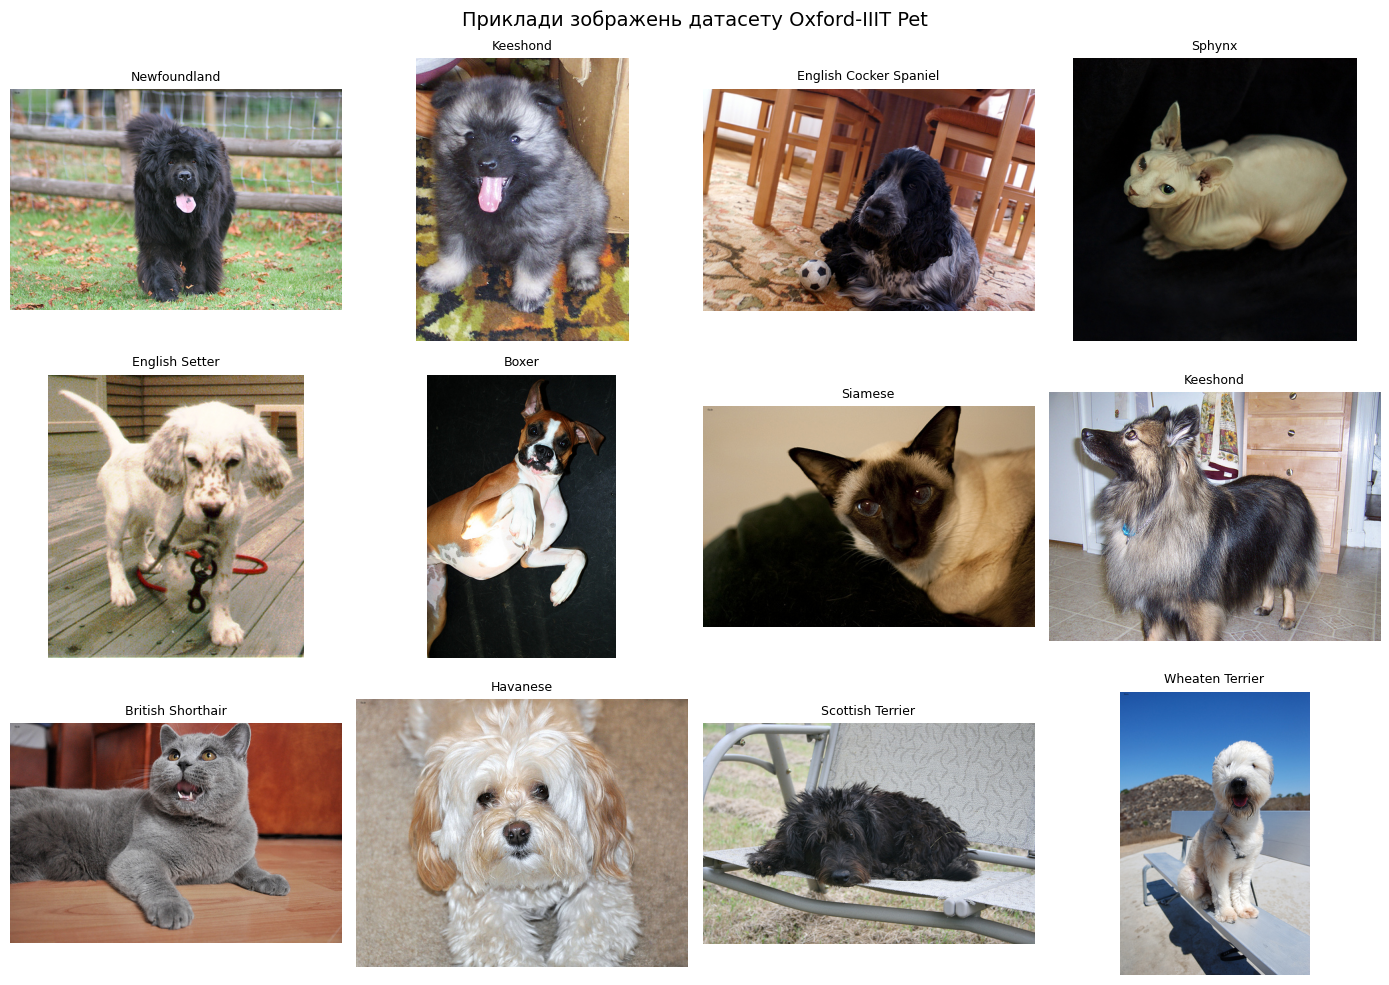

In [8]:
import matplotlib.pyplot as plt
import numpy as np

# Відображення 12 випадкових прикладів
fig, axes = plt.subplots(3, 4, figsize=(14, 10))

np.random.seed(42)
sample_indices = np.random.choice(
    len(trainval_dataset),
    size=12,
    replace=False
)

for ax, idx in zip(axes.flat, sample_indices):
    image, label = trainval_dataset[idx]

    ax.imshow(image)
    ax.set_title(class_names[label], fontsize=9)
    ax.axis("off")

plt.suptitle("Приклади зображень датасету Oxford-IIIT Pet", fontsize=14)
plt.tight_layout()
plt.show()

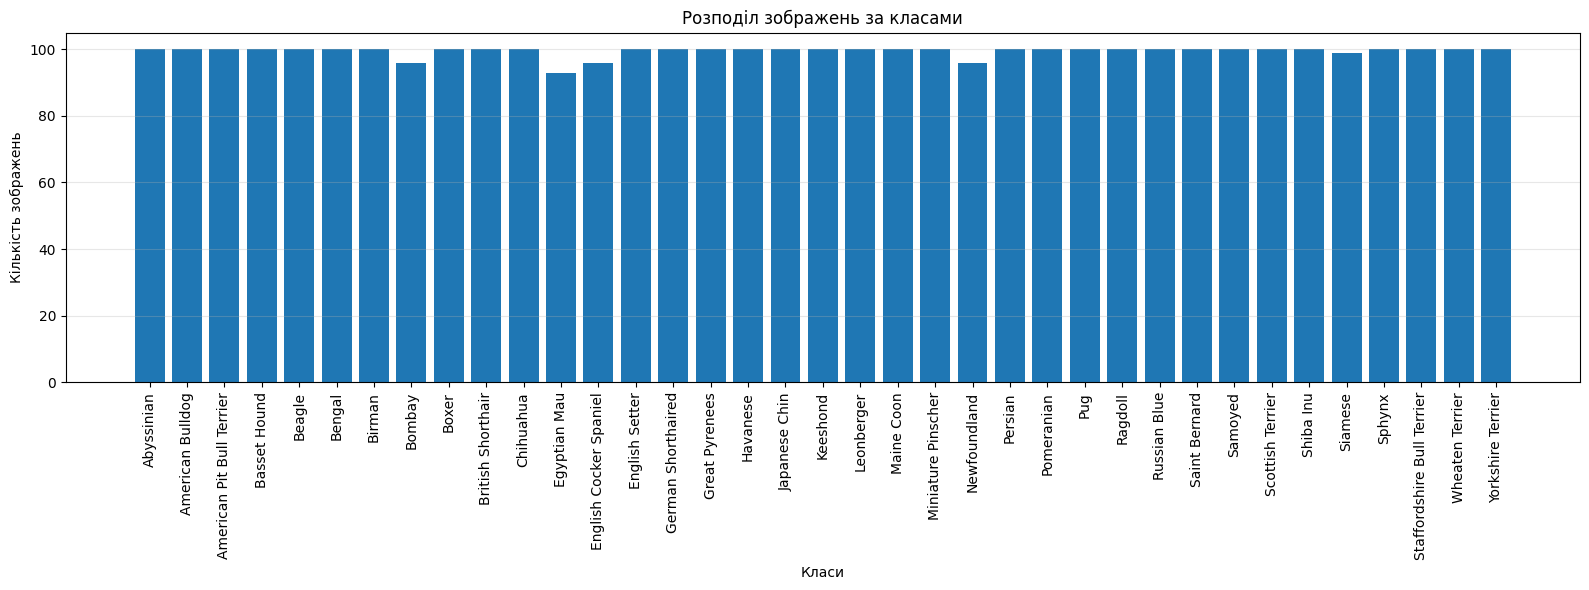

Мінімальна кількість зображень у класі: 93
Максимальна кількість зображень у класі: 100
Середня кількість зображень у класі: 99.46


In [9]:
# Підрахунок кількості зображень у кожному класі
class_counts = np.bincount(
    trainval_dataset._labels,
    minlength=num_classes
)

plt.figure(figsize=(16, 6))

plt.bar(
    class_names,
    class_counts
)

plt.title("Розподіл зображень за класами")
plt.xlabel("Класи")
plt.ylabel("Кількість зображень")
plt.xticks(rotation=90)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("Мінімальна кількість зображень у класі:", class_counts.min())
print("Максимальна кількість зображень у класі:", class_counts.max())
print("Середня кількість зображень у класі:", round(class_counts.mean(), 2))

Датасет Oxford-IIIT Pet містить 7349 зображень 37 порід котів і собак. Візуальний аналіз показав різноманітність зображень за ракурсом, освітленням, фоном і зовнішнім виглядом тварин. Розподіл зображень між класами є майже рівномірним: більшість класів містить по 100 зображень. Це дає змогу використовувати датасет для багатокласової класифікації без необхідності спеціальної корекції значного дисбалансу класів.

### **2.3. Розподіл даних і попередня обробка**

Для навчання моделей набір `trainval` поділяється на навчальну та валідаційну вибірки у співвідношенні 80:20 зі збереженням пропорцій класів за допомогою стратифікованого розбиття. Офіційний тестовий набір залишається незмінним і використовується лише для остаточного оцінювання моделей.

Для навчальної вибірки застосовуються перетворення та аугментація зображень: зміна розміру, випадкове горизонтальне відображення та нормалізація. Для валідаційної й тестової вибірок використовуються лише детерміновані перетворення. На цьому етапі розмір зображень встановлюється на рівні 128 × 128 пікселів.

In [10]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, Subset
from torchvision import transforms, datasets

indices = np.arange(len(trainval_dataset))
labels = np.array(trainval_dataset._labels)

train_indices, val_indices = train_test_split(
    indices,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Перетворення для валідаційної та тестової вибірок
eval_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Окремі екземпляри датасету з відповідними перетвореннями
train_base = datasets.OxfordIIITPet(
    root=data_dir,
    split="trainval",
    target_types="category",
    download=False,
    transform=train_transform
)

val_base = datasets.OxfordIIITPet(
    root=data_dir,
    split="trainval",
    target_types="category",
    download=False,
    transform=eval_transform
)

test_dataset = datasets.OxfordIIITPet(
    root=data_dir,
    split="test",
    target_types="category",
    download=False,
    transform=eval_transform
)

train_dataset = Subset(train_base, train_indices)
val_dataset = Subset(val_base, val_indices)

batch_size = 32

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    num_workers=0
)

print(f"Навчальна вибірка: {len(train_dataset)} зображень")
print(f"Валідаційна вибірка: {len(val_dataset)} зображень")
print(f"Тестова вибірка: {len(test_dataset)} зображень")
print(f"Кількість класів: {num_classes}")

Навчальна вибірка: 2944 зображень
Валідаційна вибірка: 736 зображень
Тестова вибірка: 3669 зображень
Кількість класів: 37


### **2.4. Перевірка підготовлених даних**

Після розподілу датасету та застосування попередньої обробки необхідно перевірити коректність підготовлених даних перед передаванням їх до нейронних мереж. Для цього аналізуються форма тензорів зображень і міток класів, тип даних, діапазон значень міток та кількість представлених класів у навчальному батчі.

Оскільки моделі CNN очікують на вхід зображення у форматі тензора, перевіряється відповідність розмірності зображень формату `(C, H, W)`, де `C` — кількість каналів, `H` і `W` — висота та ширина зображення. Також перевіряється, чи всі мітки класів належать допустимому діапазону від `0` до `num_classes - 1`.

Ці перевірки дають змогу виявити можливі помилки підготовки даних до початку навчання моделей.

In [11]:
images, labels = next(iter(train_loader))

print("Форма тензора зображень:", images.shape)
print("Форма тензора міток:", labels.shape)
print("Тип даних зображень:", images.dtype)
print("Діапазон міток:", labels.min().item(), "-", labels.max().item())
print("Кількість класів у батчі:", labels.unique().numel())

assert images.shape[1:] == (3, 128, 128)
assert labels.min().item() >= 0
assert labels.max().item() < num_classes

print("\nПеревірку формату даних успішно пройдено.")

Форма тензора зображень: torch.Size([32, 3, 128, 128])
Форма тензора міток: torch.Size([32])
Тип даних зображень: torch.float32
Діапазон міток: 0 - 36
Кількість класів у батчі: 20

Перевірку формату даних успішно пройдено.


Перевірка підготовлених даних підтвердила коректність їхнього формату для подальшого навчання згорткових нейронних мереж. Батч містить 32 зображення у форматі тензорів розмірності `(3, 128, 128)` з типом даних `float32`. Мітки класів належать допустимому діапазону, а в перевіреному батчі представлені 23 різні класи з 37 можливих.

Усі перевірки пройдено успішно, тому підготовлені дані можна використовувати для навчання моделей.

### **2.5. Побудова та навчання власної CNN**

На першому етапі класифікації зображень реалізується власна СNN без використання попередньо навчених ваг. Архітектура моделі містить три згорткові блоки, кожен із яких складається зі згорткового шару, функції активації ReLU та операції зменшення просторової розмірності MaxPooling. Після вилучення ознак результати передаються до повнозв'язних шарів, які формують прогноз належності зображення до одного з 37 класів.

Для навчання використовується оптимізатор Adam і функція втрат CrossEntropyLoss, що підходить для багатокласової класифікації. Якість навчання контролюється на валідаційній вибірці за допомогою функції втрат та accuracy. Додатково фіксуються показники для навчальної вибірки, щоб надалі проаналізувати динаміку навчання та можливе перенавчання моделі.

In [12]:

import torch
import torch.nn as nn
import torch.optim as optim

# Визначення пристрою
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Пристрій для навчання:", device)


class SimpleCNN(nn.Module):
    def __init__(self, num_classes=37):
        super(SimpleCNN, self).__init__()

        # Три згорткові шари для вилучення ознак
        self.features = nn.Sequential(
            # Перший згортковий блок
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Другий згортковий блок
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Третій згортковий блок
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2)
        )

        # Збереження просторової інформації ознак
        self.avgpool = nn.AdaptiveAvgPool2d((4, 4))

        # Повнозв'язний класифікатор
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(128 * 4 * 4, 512),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(512, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        x = self.avgpool(x)
        x = self.classifier(x)
        return x


model = SimpleCNN(num_classes=num_classes).to(device)

criterion = nn.CrossEntropyLoss()

optimizer = optim.AdamW(
    model.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

total_params = sum(p.numel() for p in model.parameters())

print(model)
print(f"\nЗагальна кількість параметрів: {total_params:,}")


Пристрій для навчання: cuda
SimpleCNN(
  (features): Sequential(
    (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    (10): ReLU(inplace=True)
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (avgpool): AdaptiveAvgPool2d(output_size=(4, 4))
  (classifier): 

In [13]:
# Перевірка прямого проходу моделі
model.eval()

with torch.no_grad():
    sample_images, sample_labels = next(iter(train_loader))
    sample_images = sample_images.to(device)

    outputs = model(sample_images)

print("Форма вхідного тензора:", sample_images.shape)
print("Форма вихідного тензора:", outputs.shape)
print("Очікувана кількість класів:", num_classes)

assert outputs.shape == (batch_size, num_classes)

print("\nПрямий прохід моделі виконано успішно.")

Форма вхідного тензора: torch.Size([32, 3, 128, 128])
Форма вихідного тензора: torch.Size([32, 37])
Очікувана кількість класів: 37

Прямий прохід моделі виконано успішно.


### **2.6. Навчання CNN**

Після побудови архітектури та успішної перевірки прямого проходу моделі виконується навчання згорткової нейронної мережі на підготовленій навчальній вибірці. Для оптимізації ваг моделі використовується алгоритм Adam із початковою швидкістю навчання 0.001, а як функція втрат — CrossEntropyLoss, що застосовується для задач багатокласової класифікації.

Навчання проводиться протягом максимум 20 епох. На кожній епосі обчислюються значення функції втрат і accuracy для навчальної та валідаційної вибірок. Це дає змогу відстежувати, наскільки добре модель засвоює ознаки зображень і узагальнює отримані знання на нових даних.

Для запобігання перенавчанню використовується механізм Early Stopping з параметром `patience = 5`. Якщо значення функції втрат на валідаційній вибірці не покращується протягом п'яти послідовних епох, навчання припиняється. Після завершення відновлюються ваги моделі, які забезпечили найменше значення validation loss.




In [20]:

import copy
import torch

num_epochs = 50
patience = 8

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "learning_rate": []
}

# Початкові параметри Early Stopping
best_val_loss = float("inf")
best_model_weights = copy.deepcopy(model.state_dict())
epochs_without_improvement = 0

for epoch in range(num_epochs):

    model.train()

    train_loss_sum = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        batch_size = labels.size(0)
        train_loss_sum += loss.item() * batch_size

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += batch_size

    train_loss = train_loss_sum / train_total
    train_acc = train_correct / train_total

    model.eval()

    val_loss_sum = 0.0
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)
            loss = criterion(outputs, labels)

            batch_size = labels.size(0)
            val_loss_sum += loss.item() * batch_size

            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += batch_size

    val_loss = val_loss_sum / val_total
    val_acc = val_correct / val_total

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)

    # Зниження learning rate за потреби
    scheduler.step(val_loss)

    current_lr = optimizer.param_groups[0]["lr"]
    history["learning_rate"].append(current_lr)

    print(
        f"Епоха [{epoch + 1}/{num_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Accuracy: {train_acc:.4f} | "
        f"Val Accuracy: {val_acc:.4f} | "
        f"LR: {current_lr:.6f}"
    )

    # EARLY STOPPING
    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_model_weights = copy.deepcopy(model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= patience:
        print(
            f"\nEarly Stopping: навчання зупинено "
            f"після {epoch + 1} епох."
        )
        break

model.load_state_dict(best_model_weights)

print("\nНавчання завершено.")
print(f"Найкращий Validation Loss: {best_val_loss:.4f}")
print(f"Кількість виконаних епох: {len(history['train_loss'])}")
print(
    f"Найкраща Validation Accuracy: "
    f"{max(history['val_acc']):.4f}"
)


Епоха [1/50] | Train Loss: 1.2653 | Val Loss: 2.4965 | Train Accuracy: 0.6148 | Val Accuracy: 0.3424 | LR: 0.000125
Епоха [2/50] | Train Loss: 1.2111 | Val Loss: 2.4934 | Train Accuracy: 0.6243 | Val Accuracy: 0.3451 | LR: 0.000125
Епоха [3/50] | Train Loss: 1.2216 | Val Loss: 2.4803 | Train Accuracy: 0.6121 | Val Accuracy: 0.3410 | LR: 0.000125
Епоха [4/50] | Train Loss: 1.2140 | Val Loss: 2.4964 | Train Accuracy: 0.6189 | Val Accuracy: 0.3505 | LR: 0.000063
Епоха [5/50] | Train Loss: 1.1979 | Val Loss: 2.4770 | Train Accuracy: 0.6185 | Val Accuracy: 0.3519 | LR: 0.000063
Епоха [6/50] | Train Loss: 1.1952 | Val Loss: 2.4746 | Train Accuracy: 0.6277 | Val Accuracy: 0.3560 | LR: 0.000063
Епоха [7/50] | Train Loss: 1.1892 | Val Loss: 2.4849 | Train Accuracy: 0.6311 | Val Accuracy: 0.3560 | LR: 0.000063
Епоха [8/50] | Train Loss: 1.1751 | Val Loss: 2.4829 | Train Accuracy: 0.6315 | Val Accuracy: 0.3533 | LR: 0.000063
Епоха [9/50] | Train Loss: 1.1655 | Val Loss: 2.4864 | Train Accuracy: 0

# **2.7. Аналіз процесу навчання згорткової нейронної мережі**

На графіках Loss та Accuracy відображено процес навчання простої CNN. Із запланованих 50 епох фактично було виконано 14 через спрацювання механізму Early Stopping.

Під час навчання Train Loss поступово зменшувався, а Train Accuracy загалом зростала. Наприкінці навчання точність на тренувальній вибірці становила 63.52%. Найменше значення Validation Loss — 2.4746 — було досягнуто на 6-й епосі, а найвища Validation Accuracy становила 35.60% на 6-й та 7-й епохах.

Помітна різниця між тренувальною та валідаційною точністю свідчить про ознаки перенавчання. Для контролю цього процесу використовувалися ReduceLROnPlateau та Early Stopping. Оскільки протягом восьми послідовних епох Validation Loss не покращувався, навчання завершилося на 14-й епосі.

Швидкість навчання поступово зменшувалася з 0.000125 до 0.000016, проте це не забезпечило подальшого суттєвого покращення валідаційних результатів.

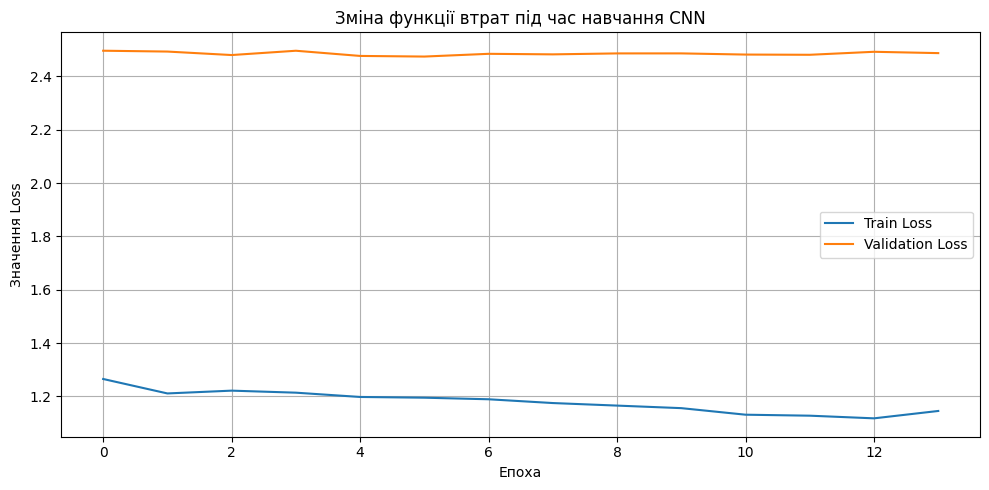

In [21]:
plt.figure(figsize=(10, 5))

plt.plot(history["train_loss"], label="Train Loss")
plt.plot(history["val_loss"], label="Validation Loss")

plt.xlabel("Епоха")
plt.ylabel("Значення Loss")
plt.title("Зміна функції втрат під час навчання CNN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

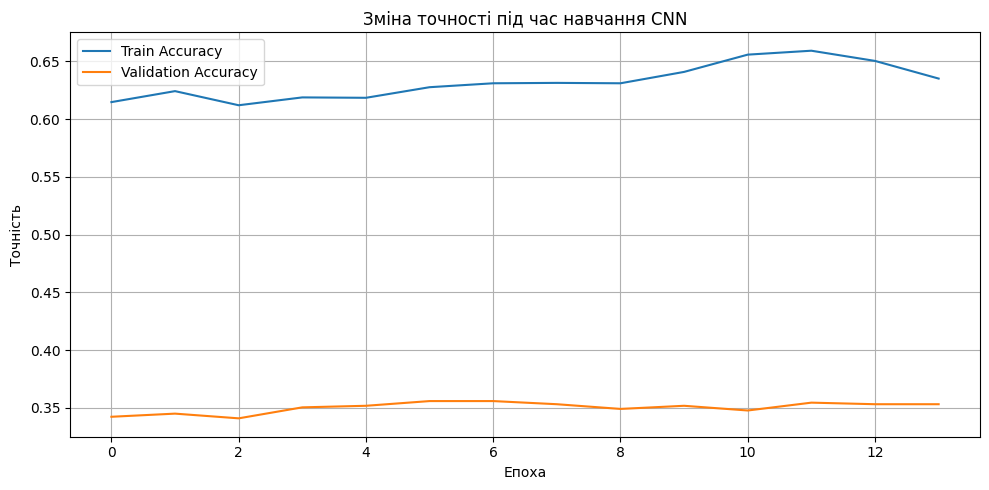

In [22]:
plt.figure(figsize=(10, 5))

plt.plot(history["train_acc"], label="Train Accuracy")
plt.plot(history["val_acc"], label="Validation Accuracy")

plt.xlabel("Епоха")
plt.ylabel("Точність")
plt.title("Зміна точності під час навчання CNN")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

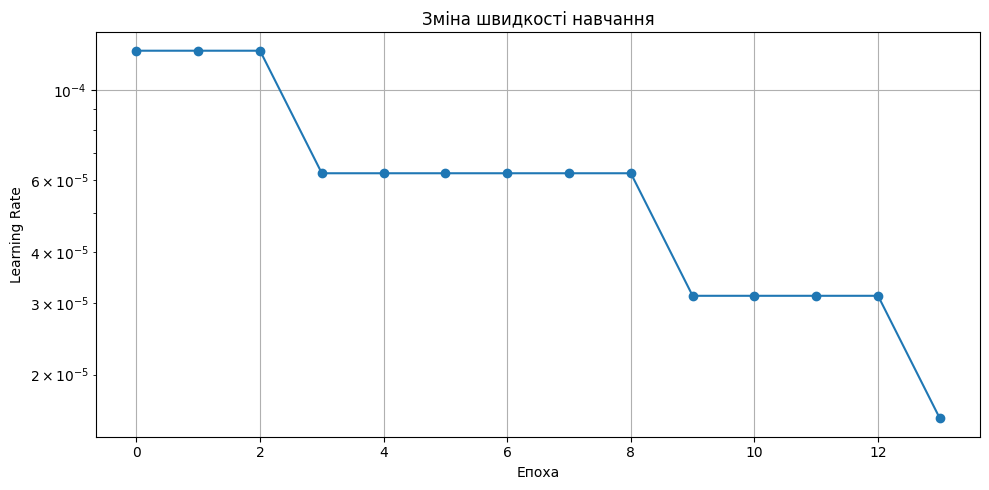

In [23]:
plt.figure(figsize=(10, 5))

plt.plot(history["learning_rate"], marker="o")

plt.xlabel("Епоха")
plt.ylabel("Learning Rate")
plt.title("Зміна швидкості навчання")
plt.yscale("log")
plt.grid(True)
plt.tight_layout()
plt.show()

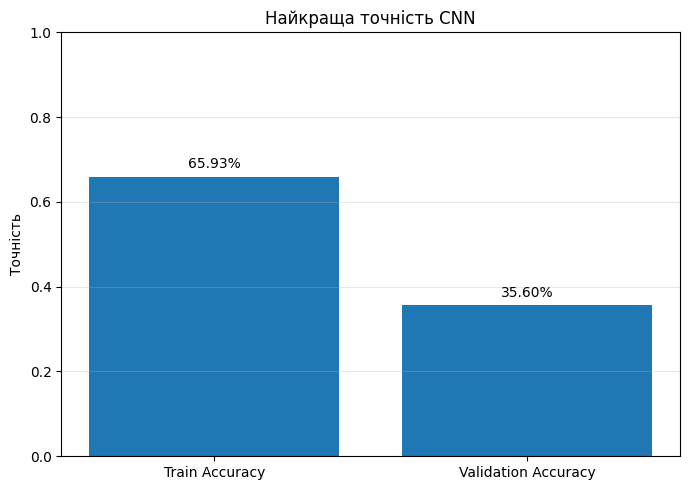

In [24]:
best_train_acc = max(history["train_acc"])
best_val_acc = max(history["val_acc"])

plt.figure(figsize=(7, 5))

bars = plt.bar(
    ["Train Accuracy", "Validation Accuracy"],
    [best_train_acc, best_val_acc]
)

plt.ylabel("Точність")
plt.title("Найкраща точність CNN")
plt.ylim(0, 1)
plt.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, [best_train_acc, best_val_acc]):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 0.02,
        f"{value:.2%}",
        ha="center"
    )

plt.tight_layout()
plt.show()

### **2.8. Оцінювання якості CNN на тестовій вибірці**

Для остаточного оцінювання моделі використаємо офіційну тестову вибірку датасету, яка містить 3669 зображень. Вона не використовувалася під час навчання моделі та підбору її параметрів.

На тестовій вибірці обчислимо Accuracy, Macro Precision, Macro Recall і Macro F1-score. Також побудуємо матрицю помилок, щоб проаналізувати правильні та помилкові класифікації для кожної породи тварин.

In [31]:
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import DataLoader

# Перетворення тестових зображень
test_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = OxfordIIITPet(
    root="./data",
    split="test",
    download=True,
    transform=test_transform,
    target_types="category"
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Кількість тестових зображень:", len(test_dataset))
print("Кількість класів:", num_classes)

Кількість тестових зображень: 3669
Кількість класів: 37


In [32]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

model.eval()

all_predictions = []
all_labels = []

with torch.inference_mode():
    for images, labels in test_loader:
        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_predictions.extend(predictions.cpu().numpy())
        all_labels.extend(labels.cpu().numpy())

print("Результати оцінювання CNN на тестовій вибірці:")
print(f"Accuracy:        {accuracy_score(all_labels, all_predictions):.4f}")
print(f"Macro Precision: {precision_score(all_labels, all_predictions, average='macro', zero_division=0):.4f}")
print(f"Macro Recall:    {recall_score(all_labels, all_predictions, average='macro', zero_division=0):.4f}")
print(f"Macro F1-score:  {f1_score(all_labels, all_predictions, average='macro', zero_division=0):.4f}")

Результати оцінювання CNN на тестовій вибірці:
Accuracy:        0.3044
Macro Precision: 0.3024
Macro Recall:    0.3050
Macro F1-score:  0.3019


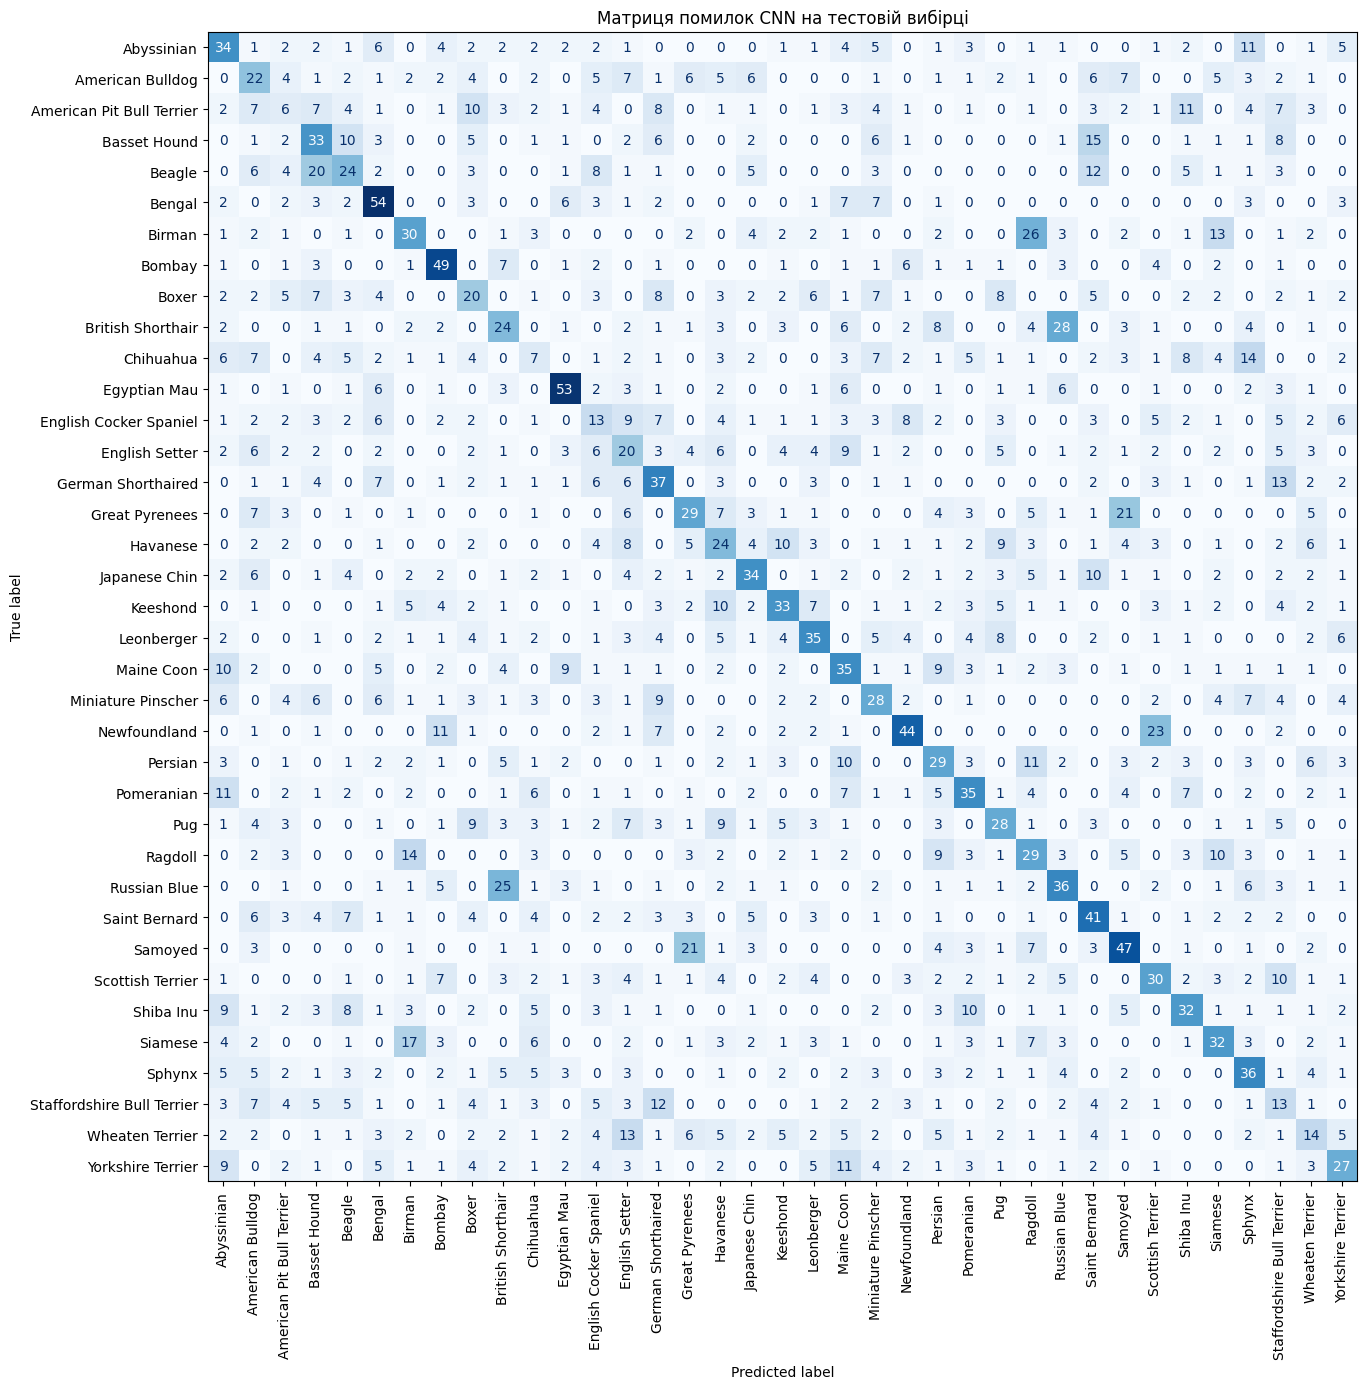

In [33]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(num_classes))
)

fig, ax = plt.subplots(figsize=(16, 14))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
).plot(
    ax=ax,
    xticks_rotation=90,
    cmap="Blues",
    colorbar=False,
    values_format="d"
)

plt.title("Матриця помилок CNN на тестовій вибірці")
plt.tight_layout()
plt.show()

### **Аналіз результатів тестування**

Після оцінювання CNN на офіційній тестовій вибірці отримано такі результати:

- Accuracy: 0.3044;
- Macro Precision: 0.3024;
- Macro Recall: 0.3050;
- Macro F1-score: 0.3019.

Отримані результати свідчать про те, що модель навчилася розпізнавати візуальні ознаки різних порід тварин, проте її точність залишається помірною. Значення Macro Precision, Macro Recall та Macro F1-score є близькими між собою, що свідчить про відсутність різкого перекосу між цими показниками.

Аналіз матриці помилок показує, що модель краще розпізнає окремі породи, тоді як деякі візуально схожі породи часто класифікуються неправильно. Наприклад, Birman може плутатися з Ragdoll, а Great Pyrenees — із Samoyed.

Таким чином, проста CNN, навчена з нуля, здатна виділяти корисні ознаки зображень, але має обмежену здатність розрізняти всі 37 класів. Для покращення результатів доцільно використати попередньо навчену згорткову нейронну мережу та порівняти її якість із розробленою моделлю.

### 2.9. Використання попередньо навченої CNN (ResNet18)

Для покращення якості класифікації використаємо попередньо навчену ResNet18 із вагами, отриманими під час навчання на ImageNet.

Оскільки початкова модель призначена для класифікації 1000 категорій, її останній повнозв'язний шар буде замінено на новий шар із 37 виходами відповідно до кількості порід у датасеті.

У межах Transfer Learning попередньо навчені параметри згорткової частини мережі будуть збережені, а новий класифікаційний шар буде навчатися для розпізнавання порід.

In [34]:
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models

# Завантаження ResNet18 з попередньо навченими вагами ImageNet
weights = models.ResNet18_Weights.DEFAULT
resnet_model = models.resnet18(weights=weights)

for param in resnet_model.parameters():
    param.requires_grad = False

# Заміна останнього шару для класифікації 37 порід
in_features = resnet_model.fc.in_features
resnet_model.fc = nn.Linear(in_features, num_classes)

resnet_model = resnet_model.to(device)

criterion_resnet = nn.CrossEntropyLoss()

optimizer_resnet = optim.Adam(
    resnet_model.fc.parameters(),
    lr=0.001
)

print(resnet_model)
print(f"\nКількість класів: {num_classes}")
print(f"Кількість параметрів класифікаційного шару: {sum(p.numel() for p in resnet_model.fc.parameters())}")

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth


100%|██████████| 44.7M/44.7M [00:00<00:00, 161MB/s]


ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

### **2.10. Підготовка даних для ResNet18**

Для використання попередньо навченої ResNet18 підготуємо зображення відповідно до вимог моделі. Зображення буде масштабовано до 224 × 224 пікселів і нормалізовано за параметрами ImageNet.

Використаємо ті самі індекси навчальної та валідаційної вибірок, що й для простої CNN. Це забезпечить коректність порівняння моделей.

In [35]:
from torchvision import transforms
from torchvision.datasets import OxfordIIITPet
from torch.utils.data import DataLoader, Subset

# Перетворення для навчальної вибірки
resnet_train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Перетворення для валідаційної та тестової вибірок
resnet_eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Окремі набори даних для навчання та валідації
resnet_train_base = OxfordIIITPet(
    root="./data",
    split="trainval",
    download=True,
    transform=resnet_train_transform,
    target_types="category"
)

resnet_val_base = OxfordIIITPet(
    root="./data",
    split="trainval",
    download=True,
    transform=resnet_eval_transform,
    target_types="category"
)

# Використання тих самих індексів розбиття
resnet_train_dataset = Subset(resnet_train_base, train_indices)
resnet_val_dataset = Subset(resnet_val_base, val_indices)

resnet_train_loader = DataLoader(
    resnet_train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0
)

resnet_val_loader = DataLoader(
    resnet_val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Train:", len(resnet_train_dataset))
print("Validation:", len(resnet_val_dataset))
print("Кількість класів:", num_classes)

Train: 2944
Validation: 736
Кількість класів: 37


In [36]:
# Перевірка розмірності даних для ResNet18

images, labels = next(iter(resnet_train_loader))

print("Форма пакета зображень:", images.shape)
print("Мінімальна мітка:", labels.min().item())
print("Максимальна мітка:", labels.max().item())
print("Кількість унікальних класів у пакеті:", labels.unique().numel())

Форма пакета зображень: torch.Size([32, 3, 224, 224])
Мінімальна мітка: 0
Максимальна мітка: 36
Кількість унікальних класів у пакеті: 24


In [37]:
# Навчання ResNet18

import copy

resnet_epochs = 15
resnet_patience = 5

resnet_history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": []
}

best_resnet_val_loss = float("inf")
best_resnet_epoch = 0
resnet_epochs_without_improvement = 0
best_resnet_weights = copy.deepcopy(resnet_model.state_dict())

for epoch in range(resnet_epochs):

    # Навчання класифікаційного шару
    resnet_model.eval()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in resnet_train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer_resnet.zero_grad()

        outputs = resnet_model(images)
        loss = criterion_resnet(outputs, labels)

        loss.backward()
        optimizer_resnet.step()

        train_loss += loss.item() * images.size(0)
        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= train_total
    train_acc = train_correct / train_total

    # Валідація
    resnet_model.eval()

    val_loss = 0.0
    val_correct = 0
    val_total = 0

    with torch.inference_mode():
        for images, labels in resnet_val_loader:
            images = images.to(device)
            labels = labels.to(device)

            outputs = resnet_model(images)
            loss = criterion_resnet(outputs, labels)

            val_loss += loss.item() * images.size(0)
            predictions = outputs.argmax(dim=1)
            val_correct += (predictions == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= val_total
    val_acc = val_correct / val_total

    resnet_history["train_loss"].append(train_loss)
    resnet_history["val_loss"].append(val_loss)
    resnet_history["train_acc"].append(train_acc)
    resnet_history["val_acc"].append(val_acc)

    print(
        f"Епоха [{epoch + 1}/{resnet_epochs}] | "
        f"Train Loss: {train_loss:.4f} | "
        f"Val Loss: {val_loss:.4f} | "
        f"Train Acc: {train_acc:.4f} | "
        f"Val Acc: {val_acc:.4f}"
    )

    # Збереження найкращої моделі
    if val_loss < best_resnet_val_loss:
        best_resnet_val_loss = val_loss
        best_resnet_epoch = epoch + 1
        best_resnet_weights = copy.deepcopy(resnet_model.state_dict())
        resnet_epochs_without_improvement = 0
    else:
        resnet_epochs_without_improvement += 1

    if resnet_epochs_without_improvement >= resnet_patience:
        print(f"\nEarly Stopping: навчання зупинено на епосі {epoch + 1}.")
        break

# Відновлення найкращих ваг
resnet_model.load_state_dict(best_resnet_weights)

print(f"\nНайкраща епоха: {best_resnet_epoch}")
print(f"Найкращий Validation Loss: {best_resnet_val_loss:.4f}")

Епоха [1/15] | Train Loss: 1.8734 | Val Loss: 0.8779 | Train Acc: 0.5778 | Val Acc: 0.8370
Епоха [2/15] | Train Loss: 0.6566 | Val Loss: 0.5403 | Train Acc: 0.8821 | Val Acc: 0.8967
Епоха [3/15] | Train Loss: 0.4457 | Val Loss: 0.4401 | Train Acc: 0.9110 | Val Acc: 0.9008
Епоха [4/15] | Train Loss: 0.3431 | Val Loss: 0.3970 | Train Acc: 0.9321 | Val Acc: 0.9008
Епоха [5/15] | Train Loss: 0.2893 | Val Loss: 0.3757 | Train Acc: 0.9385 | Val Acc: 0.8981
Епоха [6/15] | Train Loss: 0.2398 | Val Loss: 0.3568 | Train Acc: 0.9514 | Val Acc: 0.9117
Епоха [7/15] | Train Loss: 0.2078 | Val Loss: 0.3530 | Train Acc: 0.9582 | Val Acc: 0.8981
Епоха [8/15] | Train Loss: 0.1863 | Val Loss: 0.3321 | Train Acc: 0.9620 | Val Acc: 0.9090
Епоха [9/15] | Train Loss: 0.1628 | Val Loss: 0.3316 | Train Acc: 0.9698 | Val Acc: 0.8967
Епоха [10/15] | Train Loss: 0.1435 | Val Loss: 0.3099 | Train Acc: 0.9766 | Val Acc: 0.9062
Епоха [11/15] | Train Loss: 0.1327 | Val Loss: 0.3113 | Train Acc: 0.9789 | Val Acc: 0.91

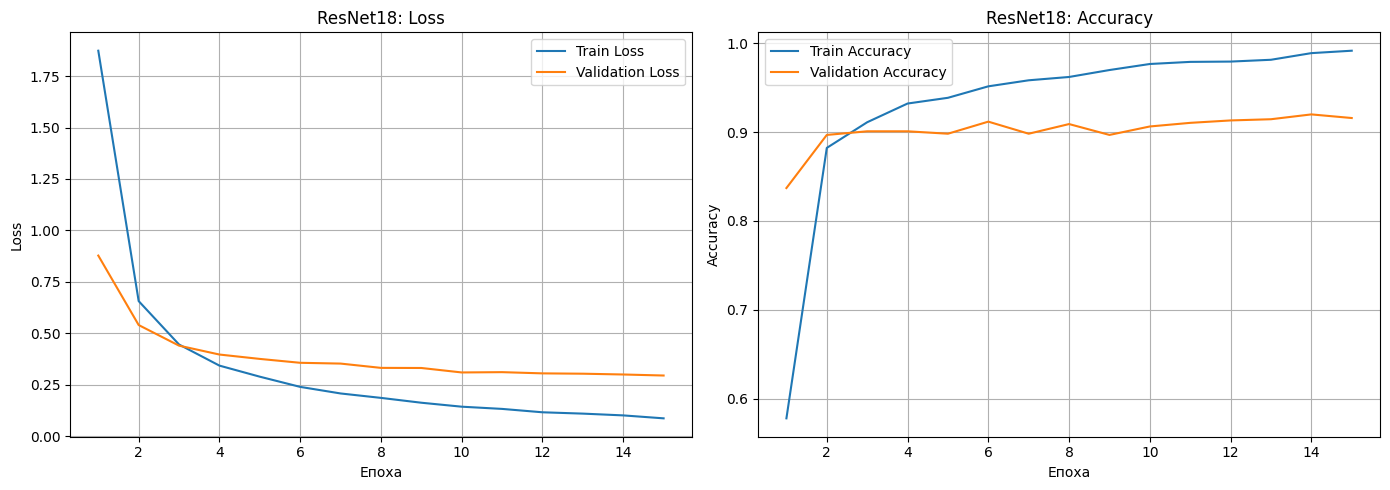

In [38]:
# Побудова графіків навчання

import matplotlib.pyplot as plt

epochs_range = range(1, len(resnet_history["train_loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Графік функції втрат
axes[0].plot(epochs_range, resnet_history["train_loss"], label="Train Loss")
axes[0].plot(epochs_range, resnet_history["val_loss"], label="Validation Loss")
axes[0].set_title("ResNet18: Loss")
axes[0].set_xlabel("Епоха")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[0].grid(True)

# Графік точності
axes[1].plot(epochs_range, resnet_history["train_acc"], label="Train Accuracy")
axes[1].plot(epochs_range, resnet_history["val_acc"], label="Validation Accuracy")
axes[1].set_title("ResNet18: Accuracy")
axes[1].set_xlabel("Епоха")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [39]:
# Підготовка тестової вибірки для ResNet18

resnet_test_dataset = OxfordIIITPet(
    root="./data",
    split="test",
    download=True,
    transform=resnet_eval_transform,
    target_types="category"
)

resnet_test_loader = DataLoader(
    resnet_test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0
)

print("Кількість тестових зображень:", len(resnet_test_dataset))
print("Кількість класів:", num_classes)

Кількість тестових зображень: 3669
Кількість класів: 37


In [40]:
# Оцінювання ResNet18 на тестовій вибірці

resnet_model.eval()

resnet_predictions = []
resnet_labels = []

with torch.inference_mode():
    for images, labels in resnet_test_loader:
        images = images.to(device)

        outputs = resnet_model(images)
        predictions = outputs.argmax(dim=1)

        resnet_predictions.extend(predictions.cpu().numpy())
        resnet_labels.extend(labels.numpy())

print("Кількість передбачень:", len(resnet_predictions))
print("Кількість правильних міток:", len(resnet_labels))

Кількість передбачень: 3669
Кількість правильних міток: 3669


In [41]:
# Обчислення метрик якості ResNet18

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

resnet_accuracy = accuracy_score(resnet_labels, resnet_predictions)

resnet_precision = precision_score(
    resnet_labels,
    resnet_predictions,
    average="macro",
    zero_division=0
)

resnet_recall = recall_score(
    resnet_labels,
    resnet_predictions,
    average="macro",
    zero_division=0
)

resnet_f1 = f1_score(
    resnet_labels,
    resnet_predictions,
    average="macro",
    zero_division=0
)

print("Результати ResNet18 на тестовій вибірці:")
print(f"Accuracy:  {resnet_accuracy:.4f}")
print(f"Precision: {resnet_precision:.4f}")
print(f"Recall:    {resnet_recall:.4f}")
print(f"F1-score:  {resnet_f1:.4f}")

Результати ResNet18 на тестовій вибірці:
Accuracy:  0.8907
Precision: 0.8924
Recall:    0.8900
F1-score:  0.8895


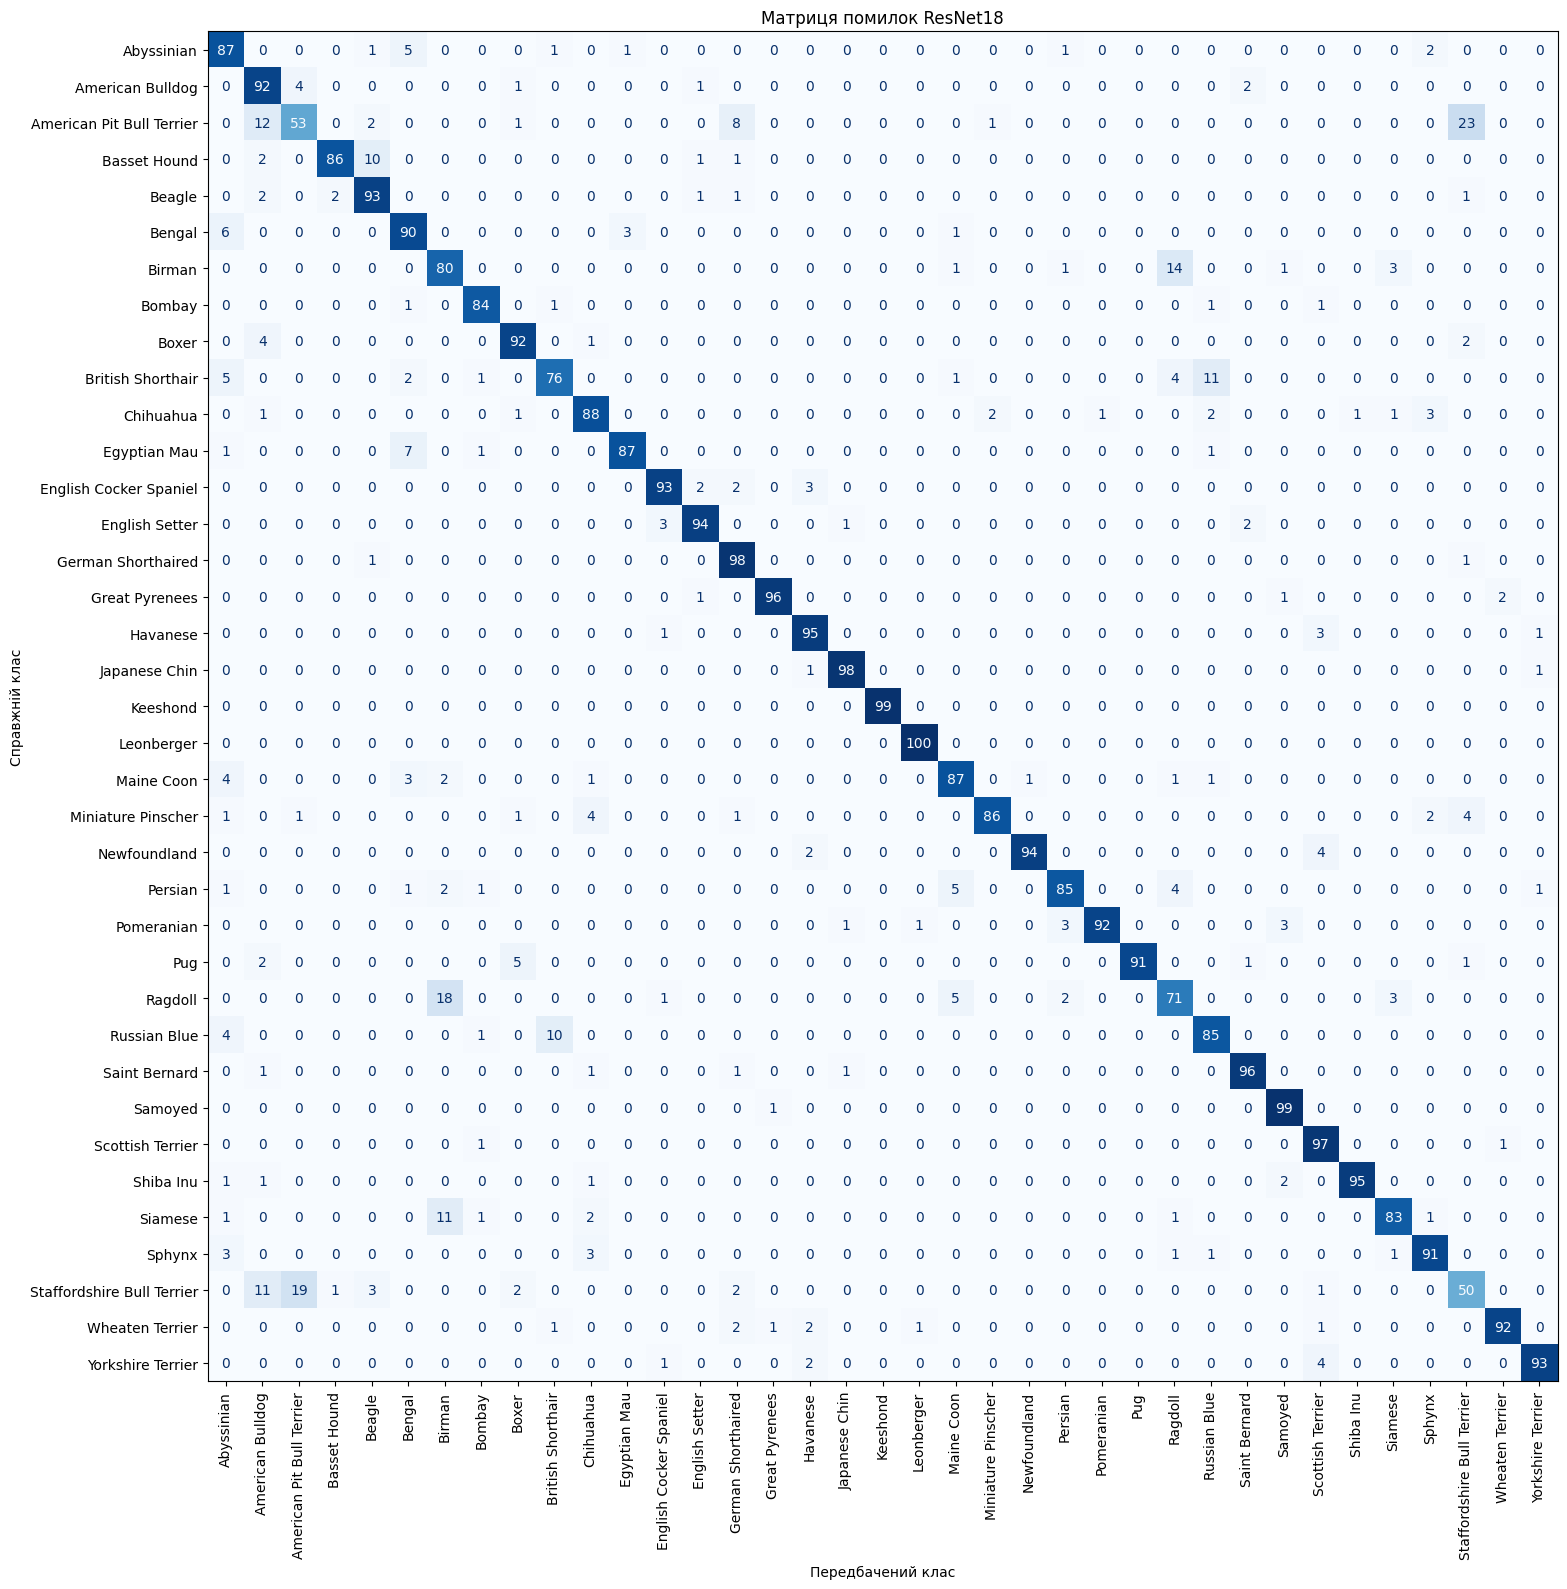

In [42]:
# Матриця помилок для ResNet18

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

resnet_cm = confusion_matrix(
    resnet_labels,
    resnet_predictions,
    labels=list(range(num_classes))
)

fig, ax = plt.subplots(figsize=(18, 16))

disp = ConfusionMatrixDisplay(
    confusion_matrix=resnet_cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=90,
    colorbar=False
)

ax.set_title("Матриця помилок ResNet18")
ax.set_xlabel("Передбачений клас")
ax.set_ylabel("Справжній клас")

plt.tight_layout()
plt.show()

Матриця помилок ResNet18 демонструє високу якість класифікації більшості порід котів і собак. Найчастіше модель плутає візуально схожі породи, зокрема Birman і Ragdoll, а також American Pit Bull Terrier і Staffordshire Bull Terrier. Загалом більшість передбачень зосереджена на головній діагоналі матриці, що підтверджує ефективність Transfer Learning. Тестова Accuracy моделі становить 89.07%.

# **2.11. Порівняння результатів Simple CNN та ResNet18**

In [43]:
# Порівняння результатів

import pandas as pd

comparison_df = pd.DataFrame({
    "Модель": ["Simple CNN", "ResNet18"],
    "Accuracy": [0.3044, resnet_accuracy],
    "Macro Precision": [0.3024, resnet_precision],
    "Macro Recall": [0.3050, resnet_recall],
    "Macro F1-score": [0.3019, resnet_f1]
})

display(comparison_df.round(4))

print(
    f"Приріст Accuracy ResNet18: "
    f"{(resnet_accuracy - 0.3044) * 100:.2f} відсоткового пункта"
)

,Модель,Accuracy,Macro Precision,Macro Recall,Macro F1-score
0,Simple CNN,0.3044,0.3024,0.305,0.3019
1,ResNet18,0.8907,0.8924,0.890,0.8895


Приріст Accuracy ResNet18: 58.63 відсоткового пункта


In [44]:
# Отримання ознак за допомогою ResNet18

feature_extractor = nn.Sequential(
    *list(resnet_model.children())[:-1]
).to(device)

feature_extractor.eval()

train_features = []
train_feature_labels = []

val_features = []
val_feature_labels = []

with torch.inference_mode():
    for images, labels in resnet_train_loader:
        images = images.to(device)
        features = feature_extractor(images).flatten(start_dim=1)

        train_features.append(features.cpu())
        train_feature_labels.append(labels)

    for images, labels in resnet_val_loader:
        images = images.to(device)
        features = feature_extractor(images).flatten(start_dim=1)

        val_features.append(features.cpu())
        val_feature_labels.append(labels)

train_features = torch.cat(train_features)
train_feature_labels = torch.cat(train_feature_labels)

val_features = torch.cat(val_features)
val_feature_labels = torch.cat(val_feature_labels)

print("Тренувальні ознаки:", train_features.shape)
print("Валідаційні ознаки:", val_features.shape)

Тренувальні ознаки: torch.Size([2944, 512])
Валідаційні ознаки: torch.Size([736, 512])


Дані: 25% | Зображень: 736 | Accuracy: 0.8315 | Macro F1: 0.8258
Дані: 50% | Зображень: 1472 | Accuracy: 0.8560 | Macro F1: 0.8546
Дані: 100% | Зображень: 2944 | Accuracy: 0.8682 | Macro F1: 0.8662

Порівняння результатів:


,Обсяг навчальних даних,Кількість зображень,Validation Accuracy,Macro F1-score
0,25%,736,0.8315,0.8258
1,50%,1472,0.8560,0.8546
2,100%,2944,0.8682,0.8662


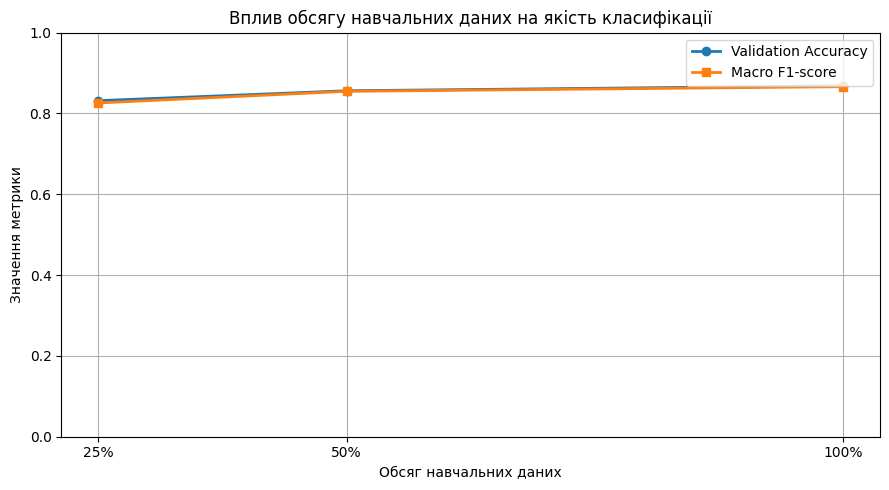

In [46]:
# Дослідження впливу обсягу навчальних даних

import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score

torch.manual_seed(42)
np.random.seed(42)

data_fractions = [0.25, 0.50, 1.00]
data_results = []

X_train = train_features.to(device)
y_train = train_feature_labels.to(device)
X_val = val_features.to(device)
y_val = val_feature_labels.to(device)

for fraction in data_fractions:

    subset_size = int(len(X_train) * fraction)

    generator = torch.Generator().manual_seed(42)
    indices = torch.randperm(
        len(X_train),
        generator=generator
    )[:subset_size]

    X_subset = X_train[indices.to(device)]
    y_subset = y_train[indices.to(device)]

    classifier = nn.Linear(512, num_classes).to(device)

    optimizer = optim.Adam(classifier.parameters(), lr=0.001)
    criterion = nn.CrossEntropyLoss()

    # Навчання класифікатора
    for epoch in range(30):
        classifier.train()

        outputs = classifier(X_subset)
        loss = criterion(outputs, y_subset)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    # Оцінювання на валідаційній вибірці
    classifier.eval()

    with torch.inference_mode():
        val_outputs = classifier(X_val)
        val_predictions = val_outputs.argmax(dim=1)

    accuracy = accuracy_score(
        y_val.cpu().numpy(),
        val_predictions.cpu().numpy()
    )

    macro_f1 = f1_score(
        y_val.cpu().numpy(),
        val_predictions.cpu().numpy(),
        average="macro",
        zero_division=0
    )

    data_results.append({
        "Обсяг навчальних даних": f"{int(fraction * 100)}%",
        "Кількість зображень": subset_size,
        "Validation Accuracy": accuracy,
        "Macro F1-score": macro_f1
    })

    print(
        f"Дані: {int(fraction * 100)}% | "
        f"Зображень: {subset_size} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Macro F1: {macro_f1:.4f}"
    )

# Формування порівняльної таблиці
data_results_df = pd.DataFrame(data_results)

print("\nПорівняння результатів:")
display(data_results_df.round(4))

fractions = [25, 50, 100]
accuracies = data_results_df["Validation Accuracy"].tolist()
f1_scores = data_results_df["Macro F1-score"].tolist()

plt.figure(figsize=(9, 5))

plt.plot(
    fractions, accuracies,
    marker="o", linewidth=2,
    label="Validation Accuracy"
)

plt.plot(
    fractions, f1_scores,
    marker="s", linewidth=2,
    label="Macro F1-score"
)

plt.xticks(fractions, ["25%", "50%", "100%"])
plt.xlabel("Обсяг навчальних даних")
plt.ylabel("Значення метрики")
plt.title("Вплив обсягу навчальних даних на якість класифікації")
plt.ylim(0, 1)
plt.grid(True)
plt.legend()

plt.tight_layout()
plt.show()



У ході дослідження було реалізовано та порівняно дві моделі класифікації зображень: власну CNN та попередньо навчену ResNet18. Експеримент показав суттєву перевагу Transfer Learning: ResNet18 досягла Accuracy 89.07%, тоді як проста CNN — 30.44%.

Також встановлено, що збільшення обсягу навчальних даних позитивно впливає на якість класифікації: Validation Accuracy зросла з 83.15% при використанні 25% даних до 86.82% при використанні повної навчальної вибірки.

Отримані результати підтверджують ефективність використання попередньо навчених згорткових мереж для класифікації зображень та демонструють важливість обсягу навчальних даних для якості моделі.